# DSR301m – SHAP: mô hình dựa vào cái gì?
**Bước 4 của Reliability & Evaluation** (LOSO → Evaluation → Ablation → **SHAP** → Figures/Report).

Theo sơ đồ Explainability của nhóm:

1. **Global** – đặc trưng nào quan trọng nhất trên toàn bộ dự đoán?
2. **Local** – vì sao một cửa sổ cụ thể được dự đoán như vậy?
3. **Reliable vs Uncertain** – giải thích có liên hệ gì với việc mô hình *chấp nhận* hay *từ chối* dự đoán?

Thêm hai kiểm tra độ tin cậy (không có trong paper): **hướng tác động có đúng sinh lý không** và **giải thích có ổn định giữa các subject không**.

> **Cách tính:** SHAP được tính **out-of-fold theo LOSO**. Mỗi subject được giải thích bởi mô hình *chưa từng thấy* subject đó. SHAP giải thích **điểm thô (log-odds) của XGBoost**. Isotonic chỉ là phép biến đổi đơn điệu nên không đổi hướng đóng góp của từng đặc trưng. Xác suất đã hiệu chuẩn `p_cal` dùng để xác định cửa sổ được chấp nhận hay bị từ chối. **SHAP giải thích hành vi của mô hình, không chứng minh quan hệ nhân quả.**

## 0. Cài đặt

In [1]:
!pip -q install shap xgboost

import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap
from scipy.stats import spearmanr, wilcoxon
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupKFold, StratifiedKFold
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

SEED = 42
TAU = 0.80                 # ngưỡng chấp nhận/từ chối (giống Evaluation/Ablation)
INNER_CV = "group"         # "group" (khuyến nghị) | "paper_cv3" | "random"  (xem notebook 01, mục 2 và 10)
FAIL_SUBJ = "S12"          # subject để phân tích thất bại (S12 = ID gốc S14)
CONFLICT_MIN = 0.25        # |SHAP nhóm| tối thiểu (log-odds) để coi là một "phiếu" rõ ràng
OUT = "results_shap"; os.makedirs(OUT, exist_ok=True)

## 1. Nạp dữ liệu & đổi tên subject S1–S15

In [2]:
DATA_PATH = "../Dataset/wesad_wrist_features.csv" if os.path.exists("../Dataset/wesad_wrist_features.csv") else "wesad_wrist_features.csv"
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()
df = pd.read_csv(DATA_PATH)
META  = ["subject_id", "time_start_sec", "time_end_sec", "label"]
FEATS = [c for c in df.columns if c not in META]
orig_ids = sorted(df.subject_id.unique(), key=lambda s: int(s[1:]))
id_map = {old: f"S{i+1}" for i, old in enumerate(orig_ids)}
df["subject_orig"] = df.subject_id
df["sid_num"] = df.subject_id.map(lambda s: int(s[1:]))
df["subject_id"] = df.subject_id.map(id_map)
df = df.sort_values(["sid_num", "time_start_sec"]).reset_index(drop=True)
SUBJECTS = [id_map[s] for s in orig_ids]
assert len(FEATS) == 25 and df.subject_id.nunique() == 15
y_all, g_all = df.label.values, df.subject_id.values
THETA = np.percentile(df.acc_mag_var, 80); HM = (df.acc_mag_var.values >= THETA)
def group_of(f):
    return {"hrv": "BVP/HRV", "eda": "EDA", "tem": "TEMP", "acc": "ACC"}[f[:3]]
GROUPS = {f: group_of(f) for f in FEATS}
GCOLS = {g: [i for i, f in enumerate(FEATS) if GROUPS[f] == g] for g in ["BVP/HRV", "EDA", "TEMP", "ACC"]}
print({g: len(c) for g, c in GCOLS.items()})


Saving wesad_wrist_features.csv to wesad_wrist_features.csv
{'BVP/HRV': 7, 'EDA': 7, 'TEMP': 5, 'ACC': 6}


## 2. LOSO: SHAP out-of-fold + xác suất đã hiệu chuẩn
Mỗi fold: scaler/mô hình fit trên 14 subject → SHAP và `p_cal` tính cho subject còn lại.

In [3]:
def inner_cv_splits(Xtr, ytr, gtr, mode=INNER_CV, seed=SEED):
    """Cách chia fold để HIỆU CHUẨN (Isotonic) bên trong 14 subject train.
    group     : GroupKFold theo subject  -> không rò rỉ giữa các cửa sổ chồng lắp, KHÔNG phụ thuộc thứ tự hàng (khuyến nghị)
    paper_cv3 : StratifiedKFold(3) không shuffle = cv=3 mặc định của sklearn -> chia theo khối liên tiếp, PHỤ THUỘC thứ tự hàng
    random    : StratifiedKFold(3, shuffle=True) -> các cửa sổ gần trùng nhau rơi vào cả hai phía -> hiệu chuẩn quá tự tin
    """
    if mode == "group":     return list(GroupKFold(n_splits=3).split(Xtr, ytr, groups=gtr))
    if mode == "paper_cv3": return list(StratifiedKFold(n_splits=3, shuffle=False).split(Xtr, ytr))
    if mode == "random":    return list(StratifiedKFold(n_splits=3, shuffle=True, random_state=seed).split(Xtr, ytr))
    raise ValueError(mode)

def make_xgb():
    return XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, subsample=0.8,
                         eval_metric="logloss", random_state=SEED, n_jobs=-1, verbosity=0)

X = df[FEATS].values
SV = np.zeros(X.shape); BASE = np.zeros(len(df)); P_RAW = np.zeros(len(df)); P_CAL = np.zeros(len(df))
t0 = time.time()
for s in SUBJECTS:
    te, tr = (g_all == s), (g_all != s)
    sc = StandardScaler().fit(X[tr]); Xtr, Xte = sc.transform(X[tr]), sc.transform(X[te])
    xg = make_xgb().fit(Xtr, y_all[tr])
    ex = shap.TreeExplainer(xg)
    SV[te] = ex.shap_values(Xte)
    BASE[te] = float(np.ravel(ex.expected_value)[0])
    P_RAW[te] = xg.predict_proba(Xte)[:, 1]
    cal = CalibratedClassifierCV(make_xgb(), method="isotonic", cv=inner_cv_splits(Xtr, y_all[tr], g_all[tr])).fit(Xtr, y_all[tr])
    P_CAL[te] = cal.predict_proba(Xte)[:, 1]
    print(f"fold {s:>3} xong ({time.time()-t0:5.1f}s)")

# kiểm tra tính cộng: base + tổng SHAP = log-odds của mô hình
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
err = np.abs((BASE + SV.sum(1)) - logit(P_RAW)).max()
print(f"Sai số tính cộng SHAP (max |base+ΣSHAP − logit(p)|) = {err:.2e}")

CONF = np.maximum(P_CAL, 1 - P_CAL); ACCEPT = CONF >= TAU
print(f"Chấp nhận {ACCEPT.mean()*100:.1f}% | từ chối {100-ACCEPT.mean()*100:.1f}% tại τ={TAU}")

shap_df = pd.DataFrame(SV, columns=[f"shap_{f}" for f in FEATS])
shap_df.insert(0, "subject_id", g_all); shap_df.insert(1, "label", y_all)
shap_df["p_raw"], shap_df["p_cal"], shap_df["base"] = P_RAW, P_CAL, BASE
shap_df.to_csv(f"{OUT}/shap_values_oof.csv", index=False)

fold  S1 xong (  2.9s)
fold  S2 xong (  8.2s)
fold  S3 xong ( 15.5s)
fold  S4 xong ( 21.8s)
fold  S5 xong ( 28.6s)
fold  S6 xong ( 33.4s)
fold  S7 xong ( 40.0s)
fold  S8 xong ( 44.3s)
fold  S9 xong ( 47.2s)
fold S10 xong ( 50.2s)
fold S11 xong ( 53.2s)
fold S12 xong ( 54.8s)
fold S13 xong ( 55.9s)
fold S14 xong ( 57.1s)
fold S15 xong ( 58.3s)
Sai số tính cộng SHAP (max |base+ΣSHAP − logit(p)|) = 9.77e-05
Chấp nhận 69.4% | từ chối 30.6% tại τ=0.8


## 3. GLOBAL – đặc trưng nào quan trọng nhất?
Bảng xếp hạng theo trung bình |SHAP|, đóng góp theo nhóm cảm biến, và beeswarm.

,feature,group,mean_abs_shap,share_%
1,eda_tonic_mean,EDA,1.2210,13.6143
2,hrv_mean_hr,BVP/HRV,1.1011,12.2764
3,temp_max,TEMP,0.9469,10.5572
4,eda_scr_peaks_count,EDA,0.9217,10.2763
5,temp_slope,TEMP,0.5797,6.4638
6,acc_mag_mean,ACC,0.5152,5.7440
7,hrv_sdnn,BVP/HRV,0.4993,5.5671
8,hrv_rmssd,BVP/HRV,0.3987,4.4448
9,acc_mag_zcr,ACC,0.3806,4.2437
10,temp_mean,TEMP,0.3787,4.2228


Đóng góp theo nhóm cảm biến (% tổng |SHAP|):
group
EDA        31.6
BVP/HRV    26.6
TEMP       25.9
ACC        15.9


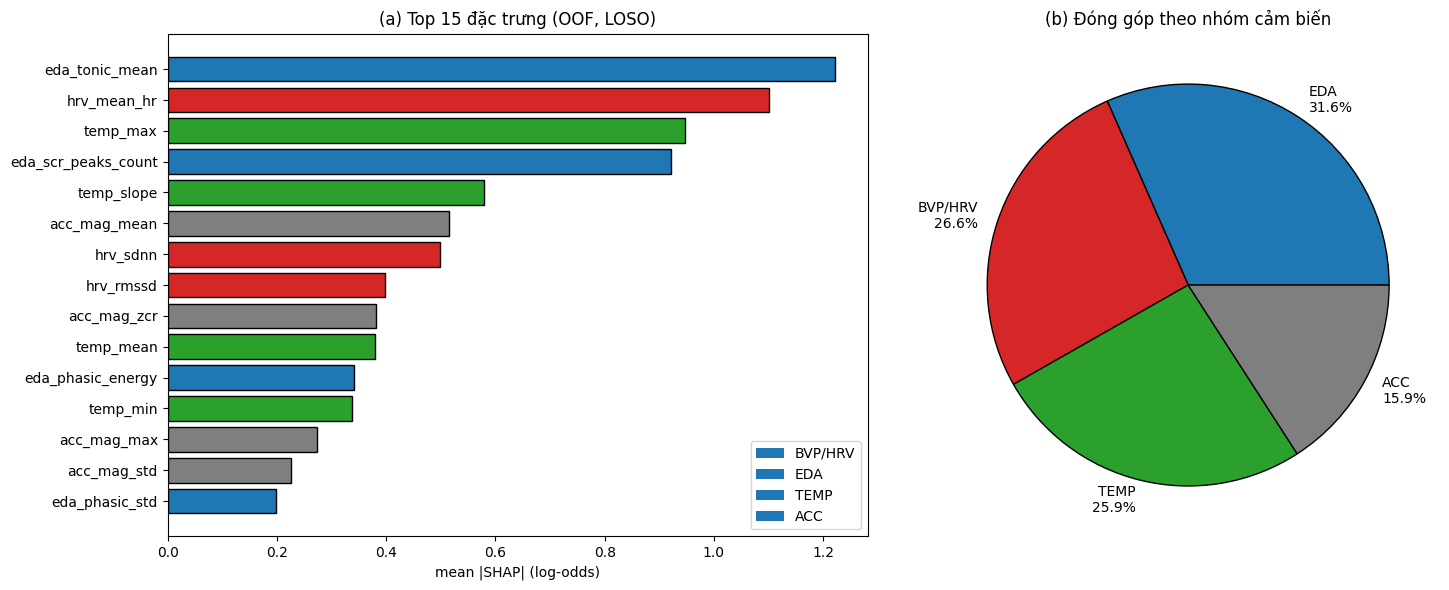

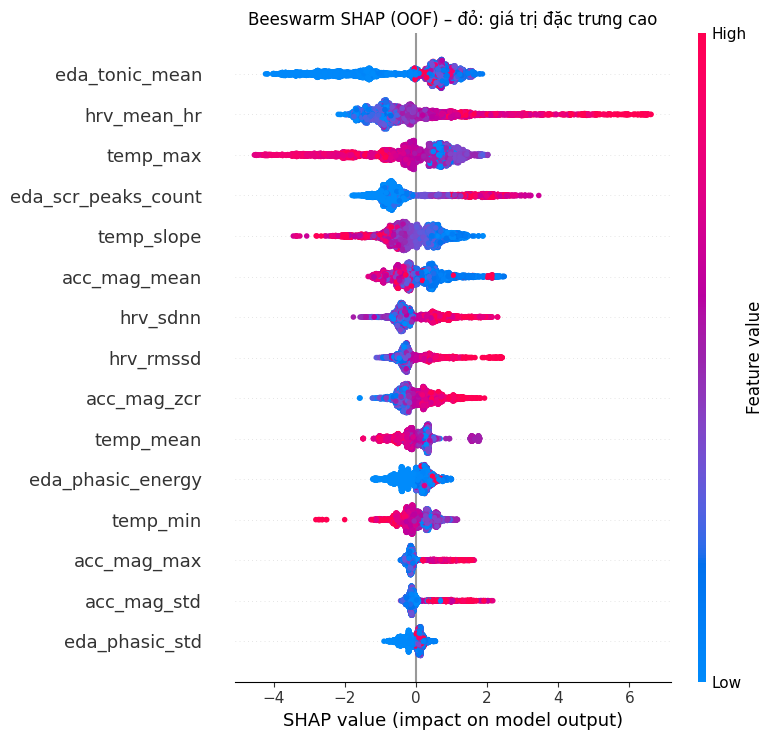

In [4]:
mabs = np.abs(SV).mean(0)
imp = pd.DataFrame({"feature": FEATS, "group": [GROUPS[f] for f in FEATS], "mean_abs_shap": mabs})
imp["share_%"] = imp.mean_abs_shap / imp.mean_abs_shap.sum() * 100
imp = imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True); imp.index += 1
imp.to_csv(f"{OUT}/global_importance.csv")
display(imp.head(15).round(4))

grp = imp.groupby("group").mean_abs_shap.sum().sort_values(ascending=False)
grp_share = (grp / grp.sum() * 100).round(1)
print("Đóng góp theo nhóm cảm biến (% tổng |SHAP|):"); print(grp_share.to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.2, 1]})
top = imp.head(15).iloc[::-1]
colors = {"BVP/HRV": "#d62728", "EDA": "#1f77b4", "TEMP": "#2ca02c", "ACC": "#7f7f7f"}
ax[0].barh(top.feature, top.mean_abs_shap, color=[colors[g] for g in top.group], edgecolor="k")
ax[0].set_xlabel("mean |SHAP| (log-odds)"); ax[0].set_title("(a) Top 15 đặc trưng (OOF, LOSO)")
for g, c in colors.items(): ax[0].barh([], [], color=c, label=g)
ax[0].legend(loc="lower right")
ax[1].pie(grp.values, labels=[f"{g}\n{v}%" for g, v in zip(grp.index, grp_share.values)],
          colors=[colors[g] for g in grp.index], wedgeprops=dict(edgecolor="k"))
ax[1].set_title("(b) Đóng góp theo nhóm cảm biến")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_shap_global_bar.png", dpi=200); plt.show()

plt.figure(figsize=(9, 7))
shap.summary_plot(SV, df[FEATS], max_display=15, show=False)
plt.title("Beeswarm SHAP (OOF) – đỏ: giá trị đặc trưng cao"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_shap_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Kiểm tra: hướng tác động có đúng sinh lý không?
Paper viết "EDA Phasic tăng cao đồng thời **RMSSD giảm sâu** → Stress". Kiểm tra bằng số liệu:

- **Kỳ vọng sinh lý**: chiều tác động theo y học (RMSSD/SDNN/pNN50/HF giảm khi stress; nhịp tim, EDA tăng; nhiệt độ da giảm).
- **Hướng trong dữ liệu**: tương quan Spearman giữa giá trị đặc trưng và nhãn Stress.
- **Hướng SHAP**: tương quan Spearman giữa giá trị đặc trưng và SHAP của chính nó (dương = giá trị cao đẩy về Stress).

Nếu *dữ liệu* đi ngược kỳ vọng thì mô hình cũng sẽ học ngược, đó là dấu hiệu của nhiễu chuyển động chứ không phải sinh lý.

In [5]:
EXPECT = {"hrv_mean_hr": +1, "hrv_rmssd": -1, "hrv_sdnn": -1, "hrv_pnn50": -1, "hrv_hf": -1, "hrv_lf_hf": +1,
          "eda_tonic_mean": +1, "eda_tonic_std": +1, "eda_phasic_mean": +1, "eda_phasic_std": +1,
          "eda_phasic_max": +1, "eda_phasic_energy": +1, "eda_scr_peaks_count": +1,
          "temp_mean": -1, "temp_slope": -1}
RHO_MIN = 0.10      # dưới ngưỡng này coi là "không rõ hướng"

rows = []
for i, f in enumerate(FEATS):
    r_data = spearmanr(X[:, i], y_all).correlation
    r_shap = spearmanr(X[:, i], SV[:, i]).correlation
    sgn = lambda r: 0 if abs(r) < RHO_MIN else int(np.sign(r))
    exp = EXPECT.get(f, 0)
    status = ("— (không có kỳ vọng)" if exp == 0 else
              "không rõ hướng" if sgn(r_shap) == 0 else
              "khớp sinh lý" if sgn(r_shap) == exp else "NGƯỢC kỳ vọng")
    rows.append(dict(feature=f, group=GROUPS[f], mean_abs_shap=mabs[i], expected=exp,
                     rho_data_vs_label=r_data, rho_value_vs_shap=r_shap, status=status))
direction = pd.DataFrame(rows).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True); direction.index += 1
direction.to_csv(f"{OUT}/direction_check.csv")
display(direction.head(15).round(3))
bad = direction[direction.status == "NGƯỢC kỳ vọng"]
print("Đặc trưng có hướng NGƯỢC kỳ vọng sinh lý (đáng chú ý nếu nằm trong top):")
print(bad[["feature", "mean_abs_shap", "rho_data_vs_label", "rho_value_vs_shap"]].round(3).to_string())

,feature,group,mean_abs_shap,expected,rho_data_vs_label,rho_value_vs_shap,status
1,eda_tonic_mean,EDA,1.221,1,0.459,0.689,khớp sinh lý
2,hrv_mean_hr,BVP/HRV,1.101,1,0.322,0.911,khớp sinh lý
3,temp_max,TEMP,0.947,0,-0.337,-0.899,— (không có kỳ vọng)
4,eda_scr_peaks_count,EDA,0.922,1,0.625,0.717,khớp sinh lý
5,temp_slope,TEMP,0.580,-1,-0.475,-0.944,khớp sinh lý
6,acc_mag_mean,ACC,0.515,0,0.009,-0.768,— (không có kỳ vọng)
7,hrv_sdnn,BVP/HRV,0.499,-1,0.543,0.715,NGƯỢC kỳ vọng
8,hrv_rmssd,BVP/HRV,0.399,-1,0.524,0.807,NGƯỢC kỳ vọng
9,acc_mag_zcr,ACC,0.381,0,0.321,0.918,— (không có kỳ vọng)
10,temp_mean,TEMP,0.379,-1,-0.339,-0.819,khớp sinh lý


Đặc trưng có hướng NGƯỢC kỳ vọng sinh lý (đáng chú ý nếu nằm trong top):
      feature  mean_abs_shap  rho_data_vs_label  rho_value_vs_shap
7    hrv_sdnn          0.499              0.543              0.715
8   hrv_rmssd          0.399              0.524              0.807
16     hrv_hf          0.147              0.513              0.926
18  hrv_pnn50          0.105              0.456              0.681


## 5. Ổn định của giải thích giữa các subject
Nếu thứ hạng đặc trưng thay đổi mạnh giữa các fold thì giải thích kém tin cậy.

Spearman trung bình giữa thứ hạng đặc trưng của các cặp fold: 0.866 (min 0.726)


,in_top5_of_15_folds,mean_rank,rank_std
eda_scr_peaks_count,15,2.9,1.2
eda_tonic_mean,14,2.9,2.7
hrv_mean_hr,13,3.6,2.9
temp_max,10,4.1,2.6
temp_slope,6,5.9,2.1
hrv_sdnn,5,7.5,3.9
acc_mag_mean,5,7.5,4.0
temp_mean,3,10.1,4.4
hrv_rmssd,2,8.9,2.6
acc_mag_max,1,12.1,4.1


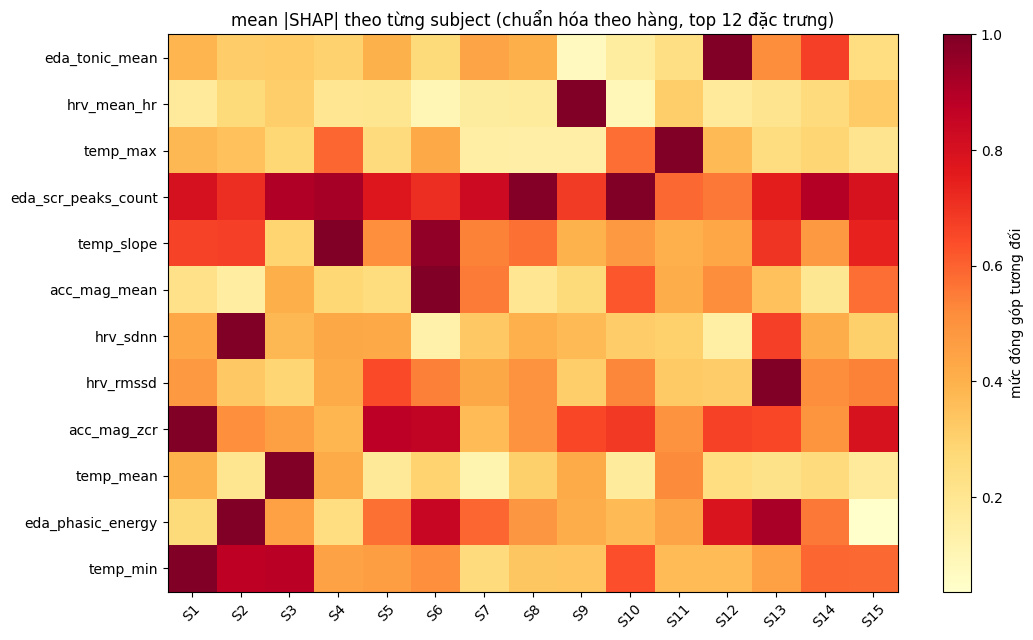

In [6]:
fold_imp = pd.DataFrame({s: np.abs(SV[g_all == s]).mean(0) for s in SUBJECTS}, index=FEATS)   # 25 x 15
rk = fold_imp.rank(ascending=False)
pair = [spearmanr(fold_imp[a], fold_imp[b]).correlation for i, a in enumerate(SUBJECTS) for b in SUBJECTS[i+1:]]
print(f"Spearman trung bình giữa thứ hạng đặc trưng của các cặp fold: {np.mean(pair):.3f} (min {np.min(pair):.3f})")

top5_freq = (rk <= 5).sum(1).sort_values(ascending=False)
stab = pd.DataFrame({"in_top5_of_15_folds": top5_freq, "mean_rank": rk.mean(1)[top5_freq.index].round(1),
                     "rank_std": rk.std(1)[top5_freq.index].round(1)})
stab.head(10).to_csv(f"{OUT}/stability_top5.csv"); display(stab.head(10))

topf = list(imp.feature.head(12))
fig, ax = plt.subplots(figsize=(11, 6.5))
M = fold_imp.loc[topf].values; M = M / M.max(1, keepdims=True)
im = ax.imshow(M, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(15)); ax.set_xticklabels(SUBJECTS, rotation=45); ax.set_yticks(range(len(topf))); ax.set_yticklabels(topf)
ax.set_title("mean |SHAP| theo từng subject (chuẩn hóa theo hàng, top 12 đặc trưng)")
plt.colorbar(im, label="mức đóng góp tương đối"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_shap_per_subject_heatmap.png", dpi=200); plt.show()

## 6. Phân tích thất bại: vì sao một subject bị dự đoán sai?
Trên các cửa sổ **Stress thật** của `FAIL_SUBJ`, so SHAP trung bình với các subject khác: đặc trưng nào kéo mô hình về phía Non-Stress?

,mean_SHAP_S12,mean_SHAP_others,diff,value_S12(z)
eda_tonic_mean,-2.654,0.569,-3.224,-0.899
eda_scr_peaks_count,-0.589,0.788,-1.377,-1.016
hrv_mean_hr,1.231,0.405,0.826,2.763
temp_slope,-0.491,0.309,-0.800,1.467
acc_mag_mean,0.797,0.036,0.761,1.089
eda_phasic_energy,-0.363,0.270,-0.634,-0.489
eda_phasic_std,-0.442,0.107,-0.549,-0.882
acc_mag_zcr,0.683,0.186,0.497,0.980
hrv_sdnn,-0.058,0.338,-0.396,-1.862
hrv_rmssd,-0.169,0.221,-0.391,-1.931


S12: 128 cửa sổ Stress | p_cal trung bình = 0.365 | tỉ lệ đoán đúng Stress (p≥0.5) = 14.1% | SHAP tổng trung bình = -1.23 (others +4.67)


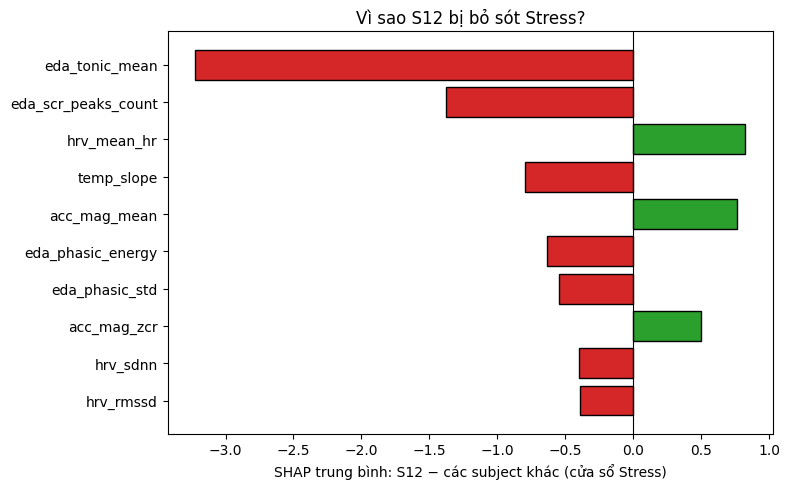

In [7]:
ms = (g_all == FAIL_SUBJ) & (y_all == 1); mo = (g_all != FAIL_SUBJ) & (y_all == 1)
diff = pd.Series(SV[ms].mean(0) - SV[mo].mean(0), index=FEATS)
tab_fail = pd.DataFrame({f"mean_SHAP_{FAIL_SUBJ}": SV[ms].mean(0), "mean_SHAP_others": SV[mo].mean(0),
                         "diff": diff, f"value_{FAIL_SUBJ}(z)": (X[ms].mean(0) - X[mo].mean(0)) / (X[mo].std(0) + 1e-9)}, index=FEATS)
tab_fail = tab_fail.reindex(diff.abs().sort_values(ascending=False).index)
tab_fail.to_csv(f"{OUT}/failure_{FAIL_SUBJ}.csv"); display(tab_fail.head(10).round(3))
print(f"{FAIL_SUBJ}: {ms.sum()} cửa sổ Stress | p_cal trung bình = {P_CAL[ms].mean():.3f} | "
      f"tỉ lệ đoán đúng Stress (p≥0.5) = {(P_CAL[ms] >= .5).mean()*100:.1f}% | "
      f"SHAP tổng trung bình = {SV[ms].sum(1).mean():+.2f} (others {SV[mo].sum(1).mean():+.2f})")

t = tab_fail.head(10).iloc[::-1]
plt.figure(figsize=(8, 5)); plt.barh(t.index, t["diff"], color=np.where(t["diff"] >= 0, "#2ca02c", "#d62728"), edgecolor="k")
plt.axvline(0, c="k", lw=.8); plt.xlabel(f"SHAP trung bình: {FAIL_SUBJ} − các subject khác (cửa sổ Stress)")
plt.title(f"Vì sao {FAIL_SUBJ} bị bỏ sót Stress?"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_failure_{FAIL_SUBJ}.png", dpi=200); plt.show()

## 7. LOCAL – vì sao một cửa sổ cụ thể được dự đoán như vậy?
Chọn các ca đại diện (xác định, không chọn tay): đúng & tin cậy (Stress / Non-Stress), bị từ chối, báo động giả khi vận động, sai nhưng tự tin.
Waterfall hiển thị trên thang **log-odds của XGBoost thô**; tiêu đề ghi cả `p_raw` và `p_cal`.

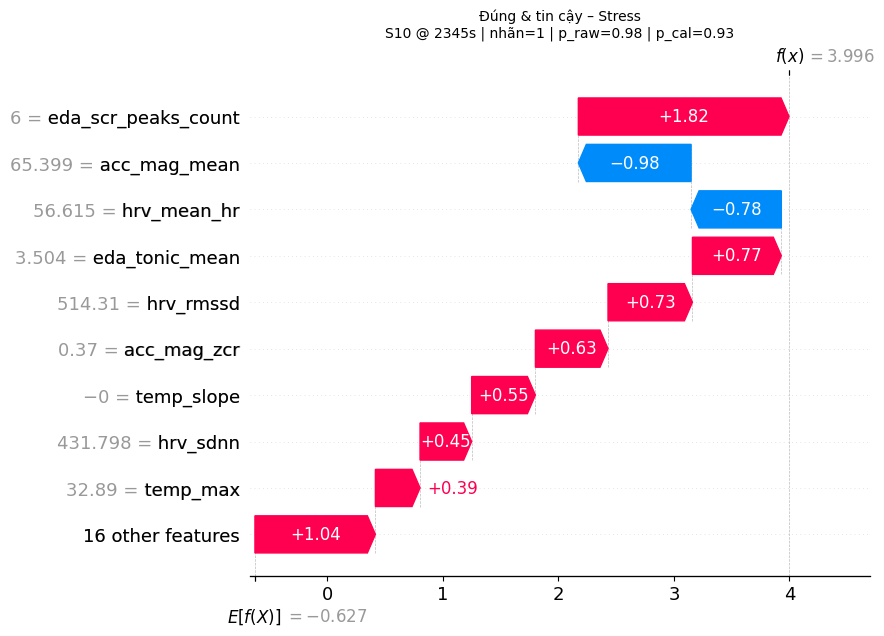

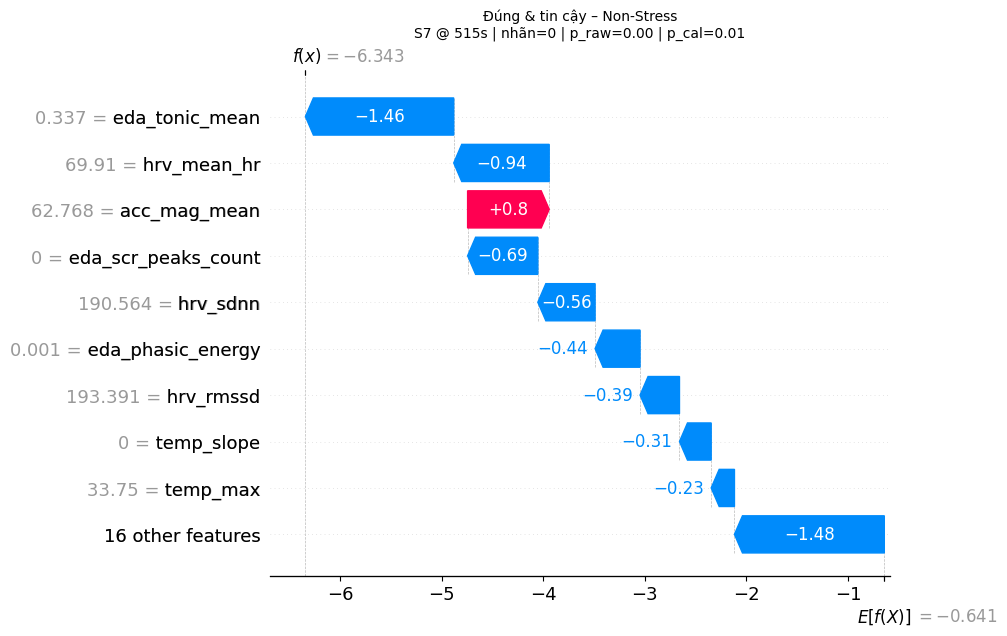

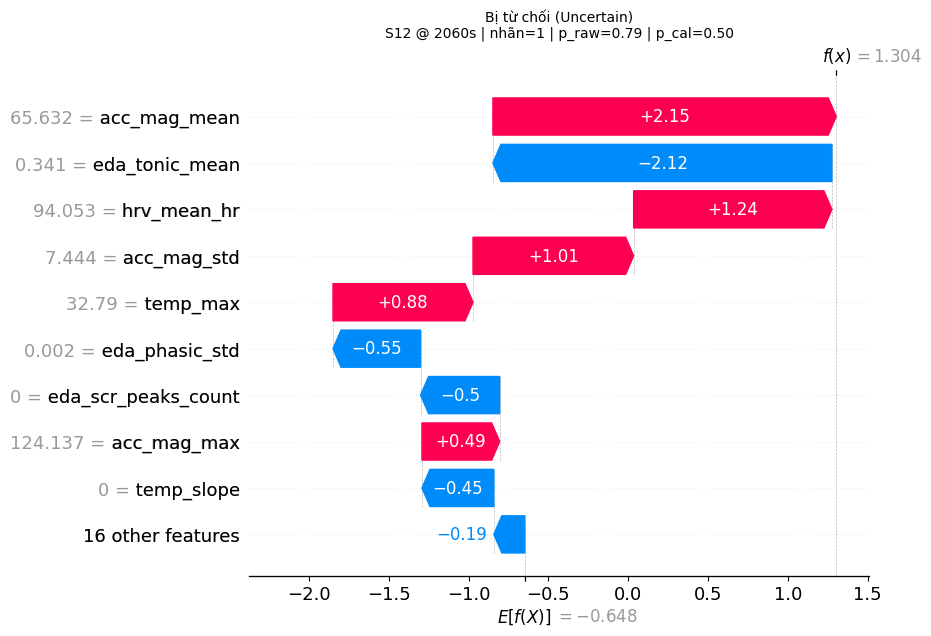

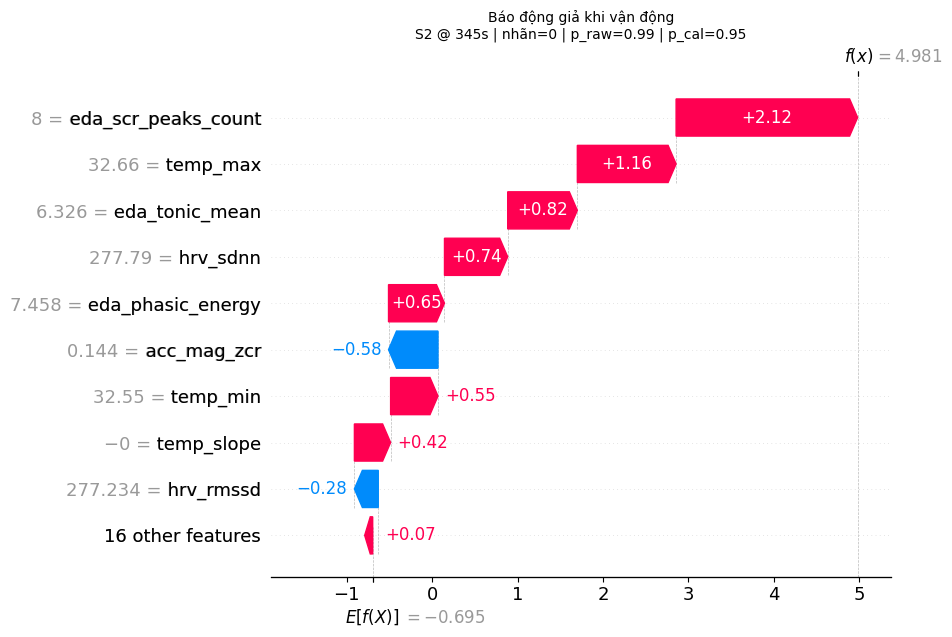

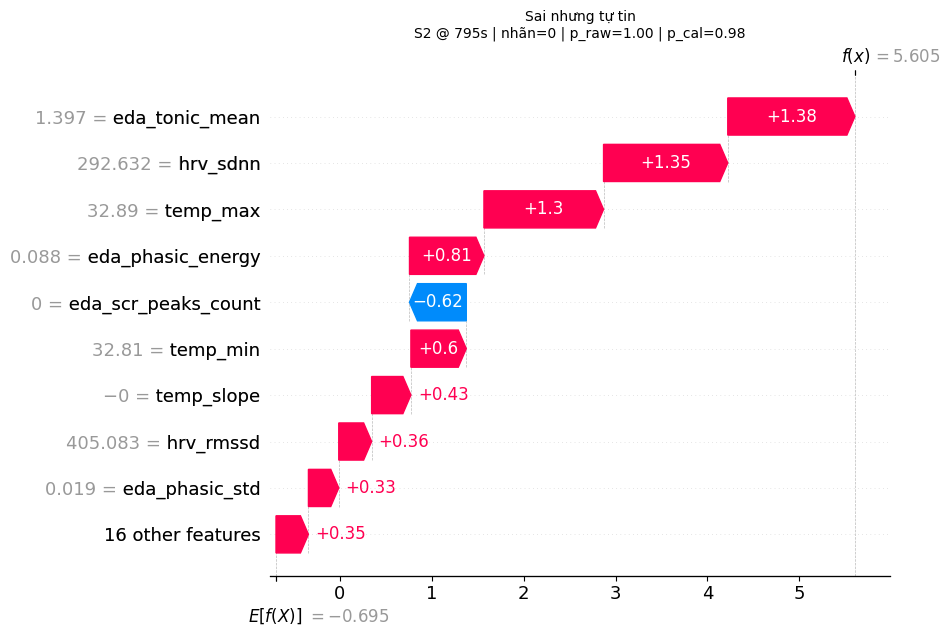

,case,subject,t_start,label,p_raw,p_cal,high_motion,accepted
0,Đúng & tin cậy – Stress,S10,2345,1,0.982,0.930,False,True
1,Đúng & tin cậy – Non-Stress,S7,515,0,0.002,0.015,False,True
2,Bị từ chối (Uncertain),S12,2060,1,0.787,0.500,True,False
3,Báo động giả khi vận động,S2,345,0,0.993,0.949,True,True
4,Sai nhưng tự tin,S2,795,0,0.996,0.980,False,True


In [8]:
def pick(mask, key, how="median"):
    idx = np.where(mask)[0]
    if len(idx) == 0: return None
    o = idx[np.argsort(key[idx])]
    return o[len(o)//2] if how == "median" else (o[0] if how == "min" else o[-1])

pred = (P_CAL >= .5).astype(int)
cases = {
  "Đúng & tin cậy – Stress":         pick((y_all == 1) & (P_CAL >= TAU), P_CAL, "median"),
  "Đúng & tin cậy – Non-Stress":     pick((y_all == 0) & (P_CAL <= 1 - TAU), P_CAL, "median"),
  "Bị từ chối (Uncertain)":          pick(~ACCEPT, CONF, "min"),
  "Báo động giả khi vận động":       pick((y_all == 0) & HM & (P_CAL >= .5), P_CAL, "max"),
  "Sai nhưng tự tin":                pick((pred != y_all) & ACCEPT, CONF, "max"),
}
SLUG = dict(zip(cases.keys(), ["dung_stress", "dung_nonstress", "uncertain", "bao_dong_gia_van_dong", "sai_tu_tin"]))
case_rows = []
for name, i in cases.items():
    if i is None: print("Không có ca:", name); continue
    case_rows.append(dict(case=name, subject=g_all[i], t_start=int(df.time_start_sec[i]), label=int(y_all[i]),
                          p_raw=P_RAW[i], p_cal=P_CAL[i], high_motion=bool(HM[i]), accepted=bool(ACCEPT[i])))
    exp = shap.Explanation(values=SV[i], base_values=BASE[i], data=X[i], feature_names=FEATS)
    plt.figure(); shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"{name}\n{g_all[i]} @ {int(df.time_start_sec[i])}s | nhãn={int(y_all[i])} | p_raw={P_RAW[i]:.2f} | p_cal={P_CAL[i]:.2f}", fontsize=10)
    plt.savefig(f"{OUT}/fig_local_{len(case_rows)}_{SLUG[name]}.png", dpi=180, bbox_inches="tight"); plt.show()
pd.DataFrame(case_rows).to_csv(f"{OUT}/local_cases.csv", index=False); pd.DataFrame(case_rows).round(3)

## 8. Reliable vs Uncertain: SHAP nói gì về cửa sổ bị từ chối?
Hai giả thuyết kiểm tra:

- **H1 – xung đột giữa các cảm biến:** khi nhóm EDA và nhóm HRV đẩy theo hai hướng ngược nhau (một bên về Stress, một bên về Non-Stress) thì tỉ lệ bị từ chối cao hơn.
- **H2 – vai trò của ACC:** tỉ lệ đóng góp |SHAP| của ACC khác nhau giữa cửa sổ vận động mạnh và nhẹ, giữa cửa sổ được chấp nhận và bị từ chối.

,mean
"ACC share % (Low motion, accepted)",13.83
"ACC share % (Low motion, rejected)",14.25
"ACC share % (High motion, accepted)",24.71
"ACC share % (High motion, rejected)",23.14


,n,tỉ lệ bị từ chối %,độ tin cậy trung bình
EDA vs HRV XUNG ĐỘT,1285,63.035,0.740
EDA & HRV ĐỒNG THUẬN,3351,18.651,0.904
không rõ (|SHAP nhóm| nhỏ),658,27.964,0.853


Wilcoxon cặp cấp subject (n=14): median tỉ lệ từ chối xung đột=53.2% vs đồng thuận=15.0% | p=0.0295


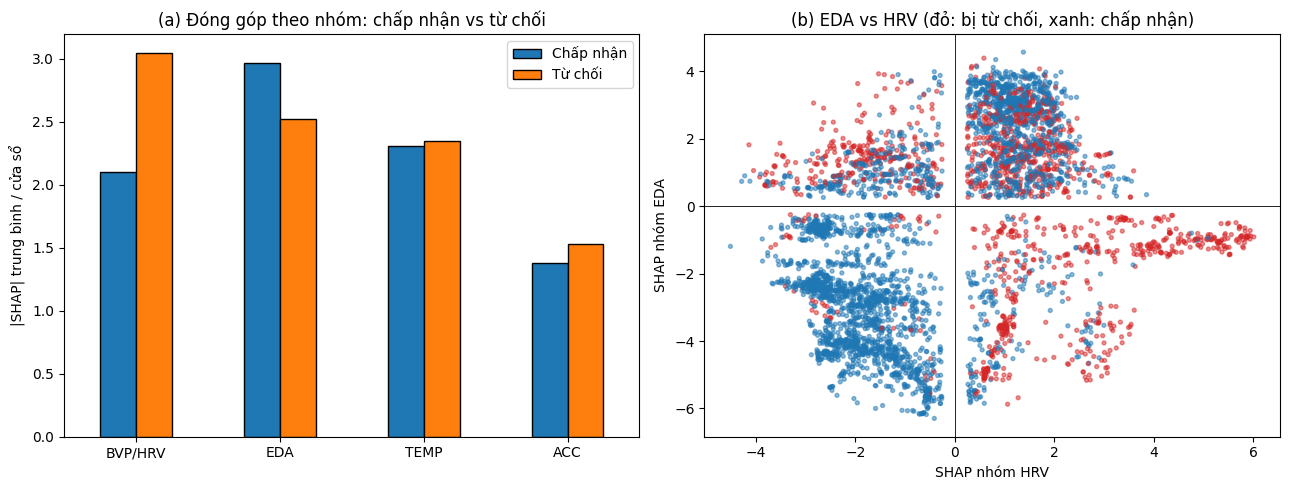

In [9]:
gs = {g: SV[:, c].sum(1) for g, c in GCOLS.items()}               # SHAP tổng theo nhóm (có dấu)
ga = {g: np.abs(SV[:, c]).sum(1) for g, c in GCOLS.items()}       # |SHAP| theo nhóm

# --- H2: tỉ lệ đóng góp của ACC ---
tot = sum(ga.values()); acc_share = ga["ACC"] / tot * 100
tabH2 = pd.DataFrame({
    "ACC share % (Low motion, accepted)":  [acc_share[(~HM) & ACCEPT].mean()],
    "ACC share % (Low motion, rejected)":  [acc_share[(~HM) & ~ACCEPT].mean()],
    "ACC share % (High motion, accepted)": [acc_share[HM & ACCEPT].mean()],
    "ACC share % (High motion, rejected)": [acc_share[HM & ~ACCEPT].mean()]}).T.rename(columns={0: "mean"})
display(tabH2.round(2))

# --- H1: xung đột EDA vs HRV ---
sE, sH = gs["EDA"], gs["BVP/HRV"]
clear = (np.abs(sE) >= CONFLICT_MIN) & (np.abs(sH) >= CONFLICT_MIN)
conflict = clear & (np.sign(sE) != np.sign(sH)); agree = clear & (np.sign(sE) == np.sign(sH))
rej = ~ACCEPT
tabH1 = pd.DataFrame({"n": [conflict.sum(), agree.sum(), (~clear).sum()],
                      "tỉ lệ bị từ chối %": [rej[conflict].mean()*100, rej[agree].mean()*100, rej[~clear].mean()*100],
                      "độ tin cậy trung bình": [CONF[conflict].mean(), CONF[agree].mean(), CONF[~clear].mean()]},
                     index=["EDA vs HRV XUNG ĐỘT", "EDA & HRV ĐỒNG THUẬN", "không rõ (|SHAP nhóm| nhỏ)"])
display(tabH1.round(3)); tabH1.to_csv(f"{OUT}/conflict_vs_rejection.csv")

# kiểm định cấp subject (tránh pseudo-replication do cửa sổ chồng lắp)
pc, pa = [], []
for s in SUBJECTS:
    m = g_all == s
    if (conflict & m).sum() >= 5 and (agree & m).sum() >= 5:
        pc.append(rej[conflict & m].mean()); pa.append(rej[agree & m].mean())
if len(pc) >= 6:
    W, p = wilcoxon(pc, pa); print(f"Wilcoxon cặp cấp subject (n={len(pc)}): median tỉ lệ từ chối xung đột={np.median(pc)*100:.1f}% vs đồng thuận={np.median(pa)*100:.1f}% | p={p:.4f}")
else:
    print(f"Chỉ {len(pc)} subject đủ mẫu ở cả hai nhóm → không đủ để kiểm định cấp subject.")

# --- hình: mean|SHAP| theo nhóm, chấp nhận vs từ chối ---
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
gm = pd.DataFrame({"Chấp nhận": {g: ga[g][ACCEPT].mean() for g in ga}, "Từ chối": {g: ga[g][~ACCEPT].mean() for g in ga}})
gm.plot.bar(ax=ax[0], edgecolor="k", rot=0); ax[0].set_ylabel("|SHAP| trung bình / cửa sổ"); ax[0].set_title("(a) Đóng góp theo nhóm: chấp nhận vs từ chối")
ax[1].scatter(sH[clear], sE[clear], c=np.where(rej[clear], "#d62728", "#1f77b4"), s=8, alpha=.5)
ax[1].axhline(0, c="k", lw=.6); ax[1].axvline(0, c="k", lw=.6); ax[1].set_xlabel("SHAP nhóm HRV"); ax[1].set_ylabel("SHAP nhóm EDA")
ax[1].set_title("(b) EDA vs HRV (đỏ: bị từ chối, xanh: chấp nhận)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_shap_reliable_vs_uncertain.png", dpi=200); plt.show()

## 9. Tóm tắt để dán vào báo cáo

In [10]:
print("TOP-5 đặc trưng (mean |SHAP|):", ", ".join(imp.feature.head(5)))
print("Đóng góp theo nhóm (%):", grp_share.to_dict())
n_bad_top = (direction.head(10).status == "NGƯỢC kỳ vọng").sum()
print(f"Trong top-10: {n_bad_top} đặc trưng có hướng SHAP ngược kỳ vọng sinh lý →",
      direction.head(10)[direction.head(10).status == "NGƯỢC kỳ vọng"].feature.tolist())
print(f"Ổn định thứ hạng giữa các fold: Spearman TB = {np.mean(pair):.3f}")
print(f"Từ chối khi EDA–HRV xung đột: {tabH1.iloc[0,1]:.1f}% vs đồng thuận: {tabH1.iloc[1,1]:.1f}%")

TOP-5 đặc trưng (mean |SHAP|): eda_tonic_mean, hrv_mean_hr, temp_max, eda_scr_peaks_count, temp_slope
Đóng góp theo nhóm (%): {'EDA': 31.6, 'BVP/HRV': 26.6, 'TEMP': 25.9, 'ACC': 15.9}
Trong top-10: 2 đặc trưng có hướng SHAP ngược kỳ vọng sinh lý → ['hrv_sdnn', 'hrv_rmssd']
Ổn định thứ hạng giữa các fold: Spearman TB = 0.866
Từ chối khi EDA–HRV xung đột: 63.0% vs đồng thuận: 18.7%


## 10. Lưu kết quả lên Google Drive

In [11]:
try:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/DSR301m_project_group4/result/SHap"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    shutil.copytree(OUT, DRIVE_DIR, dirs_exist_ok=True)
    print("Đã lưu vào:", DRIVE_DIR); print(sorted(os.listdir(DRIVE_DIR)))
except ImportError:
    print("Không chạy trên Colab → bỏ qua bước lưu Drive. Kết quả nằm trong:", OUT)

Mounted at /content/drive
Đã lưu vào: /content/drive/MyDrive/DSR301m_project_group4/result/SHap
['conflict_vs_rejection.csv', 'direction_check.csv', 'failure_S12.csv', 'fig_failure_S12.png', 'fig_local_1_dung_stress.png', 'fig_local_2_dung_nonstress.png', 'fig_local_3_uncertain.png', 'fig_local_4_bao_dong_gia_van_dong.png', 'fig_local_5_sai_tu_tin.png', 'fig_shap_beeswarm.png', 'fig_shap_global_bar.png', 'fig_shap_per_subject_heatmap.png', 'fig_shap_reliable_vs_uncertain.png', 'global_importance.csv', 'local_cases.csv', 'shap_values_oof.csv', 'stability_top5.csv']
